In [1]:
!pip install ultralytics
!wandb disabled

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 914.8/914.8 kB 22.4 MB/s eta 0:00:0000:01
W&B disabled.


In [2]:
import os

def count_images_in_directory(directory, extensions=['.jpg', '.jpeg', '.png', '.bmp', '.gif']):
    count = 0
    for root, dirs, files in os.walk(directory):
        count += sum(1 for file in files if file.lower().endswith(tuple(extensions)))
    return count

# Replace 'your_directory_path' with the path to your dataset
directory_path = '/kaggle/input/fire-detectionn'
image_count = count_images_in_directory(directory_path)
print(f"Total images in directory: {image_count}")


Total images in directory: 15551


In [3]:
!yolo train model=yolov8n.pt data=/kaggle/input/fire-detectionn/data.yaml 
                             epochs=50 
                             imgsz=640 
                             batch=32

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
100%|███████████████████████████████████████| 6.25M/6.25M [00:00<00:00, 104MB/s]
Ultralytics 8.3.72 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/kaggle/input/fire-detectionn/data.yaml, epochs=50, time=None, patience=100, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4

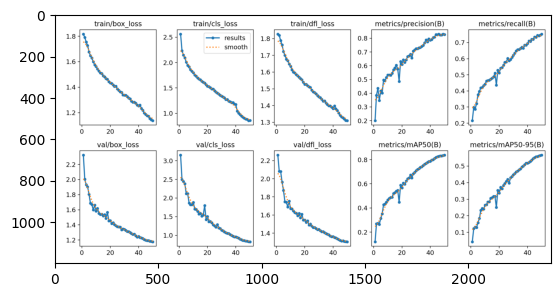

In [4]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/kaggle/working/runs/detect/train/results.png')
imgplot = plt.imshow(img)
plt.show()

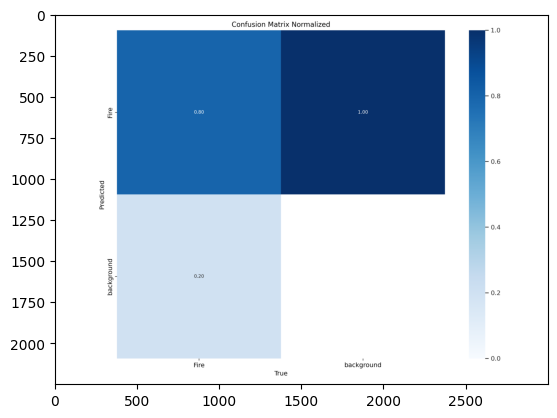

In [5]:
img = mpimg.imread('/kaggle/working/runs/detect/train/confusion_matrix_normalized.png')
imgplot = plt.imshow(img)
plt.show()

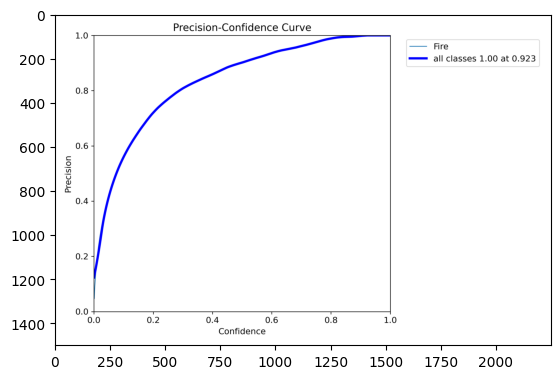

In [6]:
img = mpimg.imread('/kaggle/working/runs/detect/train/P_curve.png')
imgplot = plt.imshow(img)
plt.show()

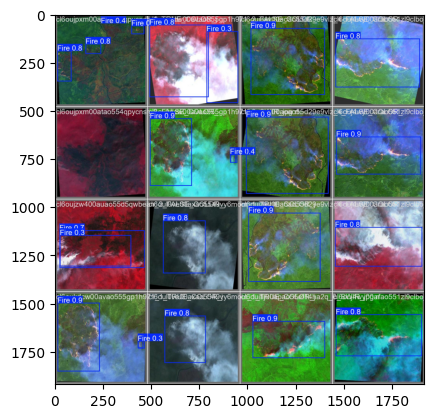

In [7]:
img = mpimg.imread('/kaggle/working/runs/detect/train/val_batch0_pred.jpg')
imgplot = plt.imshow(img)
plt.show()

In [8]:
!yolo task=detect mode=predict model="/kaggle/working/runs/detect/train/weights/best.pt" device=0 source="/kaggle/input/fire-detectionn/test/images" save=True

Ultralytics 8.3.72 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 168 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs

image 1/1555 /kaggle/input/fire-detectionn/test/images/cl6aniex40000f0559xrzal6j_2_FALSE_COLOR_jpg.rf.c3b6cee2899d5efae138b7e4d9274f24.jpg: 640x640 1 Fire, 5.9ms
image 2/1555 /kaggle/input/fire-detectionn/test/images/cl6aniex40000f0559xrzal6j_4_FALSE_COLOR__URBAN_jpg.rf.f3d153e3628b4ba1fb627fb23d1aaaf5.jpg: 640x640 1 Fire, 6.0ms
image 3/1555 /kaggle/input/fire-detectionn/test/images/cl6aniex40000f0559xrzal6j_6_SWIR_jpg.rf.a3723fc42c06517b0db04889107d9631.jpg: 640x640 1 Fire, 5.6ms
image 4/1555 /kaggle/input/fire-detectionn/test/images/cl6anjur50001f055bzb494if_2_FALSE_COLOR_jpg.rf.88f908d40a6bb5410fcf0896347b1c27.jpg: 640x640 2 Fires, 5.6ms
image 5/1555 /kaggle/input/fire-detectionn/test/images/cl6anjur50001f055bzb494if_4_FALSE_COLOR__URBAN_jpg.rf.a16fe6025d143155bca101844fac4eda.jpg: 640x640 2 Fires, 5.4ms
image 6/155

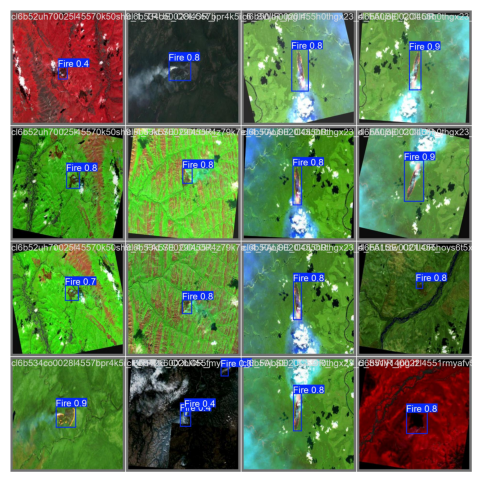

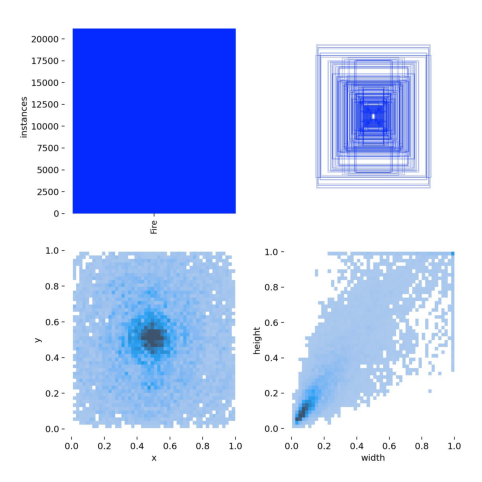

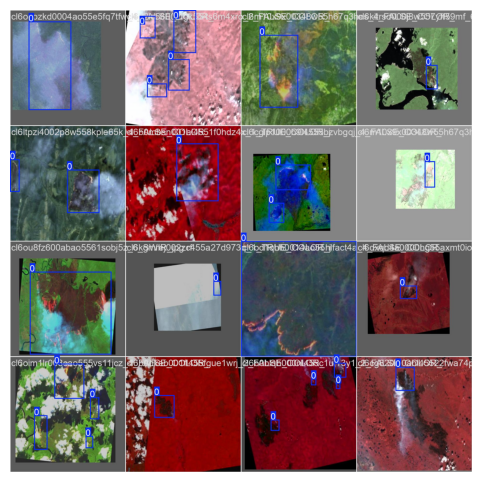

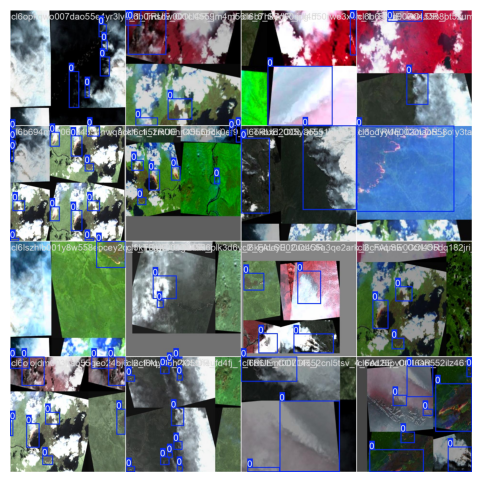

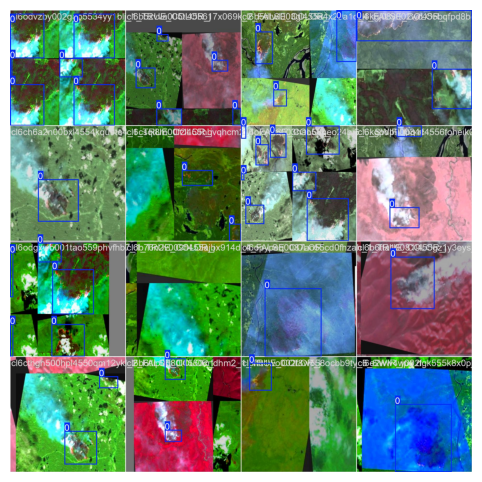

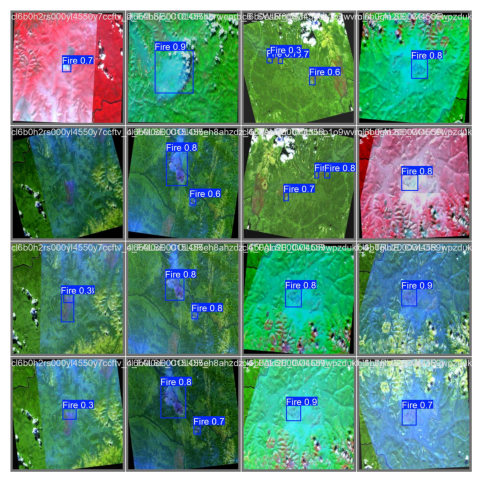

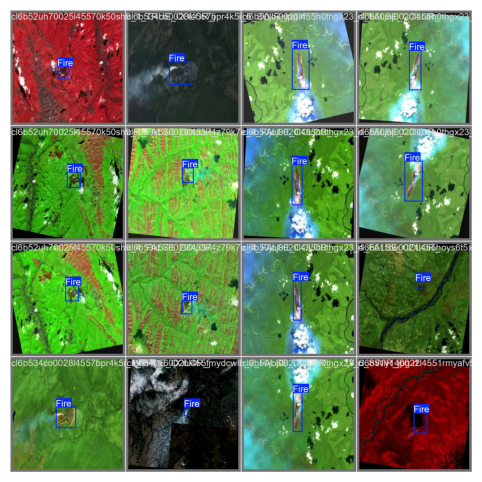

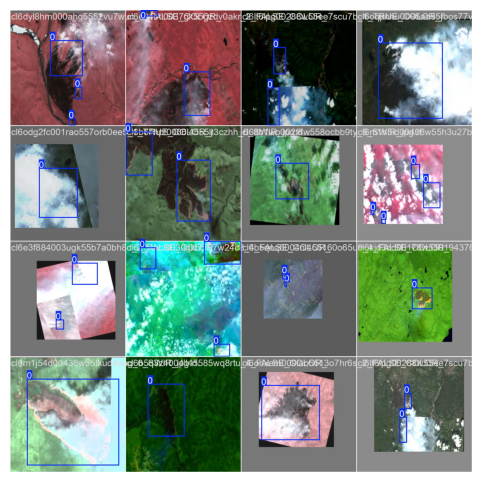

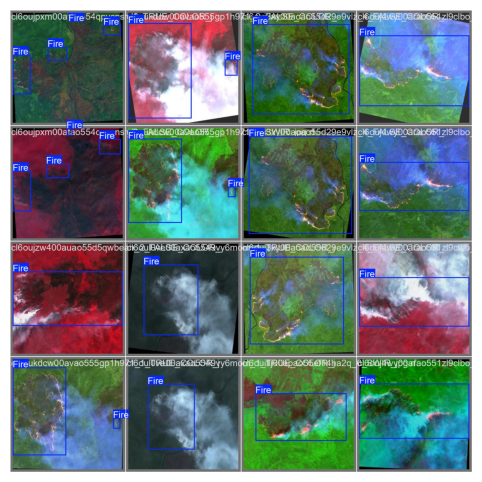

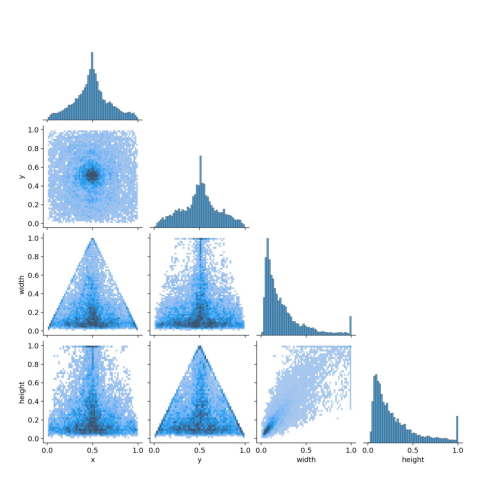

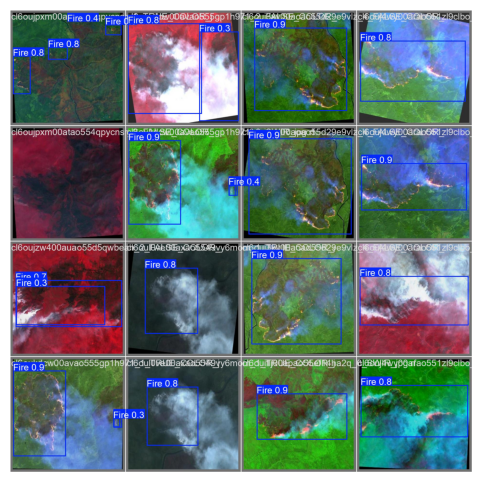

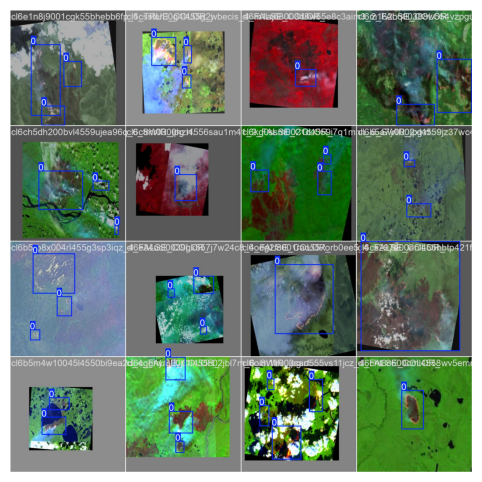

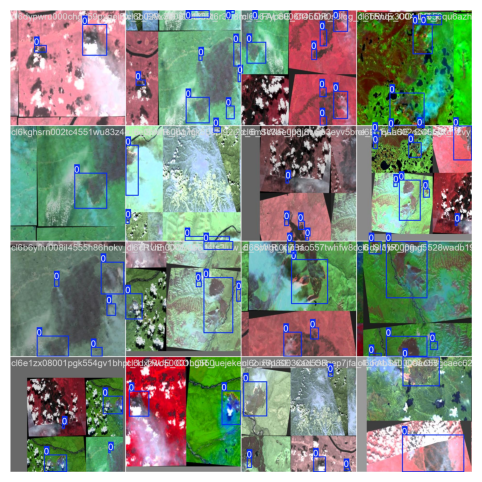

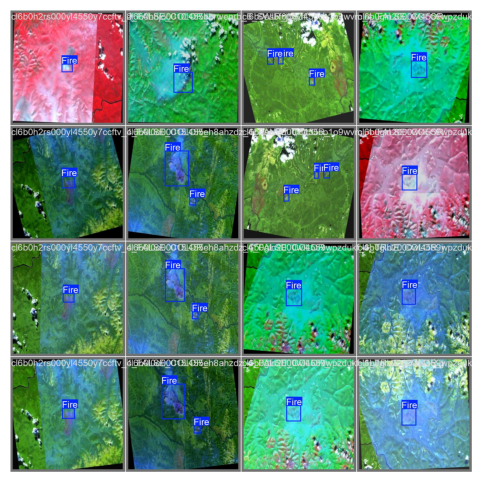

In [9]:
import cv2
import matplotlib.pyplot as plt
from glob import glob

# Load images from YOLO prediction results
img_paths = glob('/kaggle/working/runs/detect/train/*.jpg')  # Adjust path if needed

if not img_paths:
    print("No detected images found.")
else:
    for img_path in img_paths:
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert from OpenCV BGR to RGB for Matplotlib

        plt.figure(figsize=(8, 6))
        plt.imshow(img)
        plt.axis("off")
        plt.show()


YOLO  V5

In [10]:

!git clone https://github.com/ultralytics/yolov5  # clone
%cd yolov5
%pip install -qr requirements.txt comet_ml  # install

import torch
import utils
display = utils.notebook_init()  # checks

YOLOv5 🚀 v7.0-398-g5cdad892 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)


Setup complete ✅ (4 CPUs, 31.4 GB RAM, 6096.0/8062.4 GB disk)


In [11]:
!python detect.py --weights yolov5s.pt --img 640 --conf 0.25 --source data/images

detect: weights=['yolov5s.pt'], source=data/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-398-g5cdad892 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)

100%|███████████████████████████████████████| 14.1M/14.1M [00:00<00:00, 112MB/s]

Fusing layers... 
YOLOv5s summary: 213 layers, 7225885 parameters, 0 gradients, 16.4 GFLOPs
image 1/2 /kaggle/working/yolov5/data/images/bus.jpg: 640x480 4 persons, 1 bus, 43.2ms
image 2/2 /kaggle/working/yolov5/data/images/zidane.jpg: 384x640 2 persons, 2 ties, 40.5ms
Speed: 0.5ms pre-process, 41.9ms inference, 69.9ms NMS per image at shape 

In [12]:
yaml_path = "/kaggle/input/fire-detection2/data.yaml"

# Read the file
with open(yaml_path, "r") as f:
    data = f.read()

# Modify the content
data = data.replace("../train/images", "/kaggle/input/fire-detection2/train/images")
data = data.replace("../valid/images", "/kaggle/input/fire-detection2/valid/images")
data = data.replace("../test/images", "/kaggle/input/fire-detection2/test/images")

# Save the changes to a new writable file
with open("/kaggle/working/data.yaml", "w") as f:
    f.write(data)

print("Updated data.yaml saved at /kaggle/working/data.yaml")


Updated data.yaml saved at /kaggle/working/data.yaml


In [13]:
!yolo train model=yolov8n.pt data=/kaggle/working/data.yaml epochs=50 imgsz=640 batch=32


100%|███████████████████████████████████████| 6.25M/6.25M [00:00<00:00, 114MB/s]
Ultralytics 8.3.72 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/kaggle/working/data.yaml, epochs=50, time=None, patience=100, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt

In [14]:
!yolo detect val model=runs/detect/train/weights/best.pt data=/kaggle/input/fire-detection2/data.yaml plots=True imgsz=640 batch=16 device=0

Ultralytics 8.3.72 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 168 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Scanning /kaggle/input/fire-detection2/valid/labels... 75 images, 1 backgro
val: WARNING ⚠️ Cache directory /kaggle/input/fire-detection2/valid is not writeable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  m
                   all         75        156      0.587      0.462      0.506      0.272
Speed: 5.1ms preprocess, 4.2ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


In [15]:
t ensorboard --logdir=runs/detect/train

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (980963944.py, line 1)